In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [49]:
df = pd.read_csv("/content/employeeee.csv")

In [50]:
df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot,RecordType
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0,Original
1,Bachelors,2013,Pune,1,28,Female,No,3,1,Original
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0,Original
3,Masters,2016,Bangalore,3,27,Male,No,5,1,Original
4,Masters,2017,Pune,3,24,Male,Yes,2,1,Original


In [51]:
df.shape

(9306, 10)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9306 entries, 0 to 9305
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  9306 non-null   object
 1   JoiningYear                9306 non-null   int64 
 2   City                       9306 non-null   object
 3   PaymentTier                9306 non-null   int64 
 4   Age                        9306 non-null   int64 
 5   Gender                     9306 non-null   object
 6   EverBenched                9306 non-null   object
 7   ExperienceInCurrentDomain  9306 non-null   int64 
 8   LeaveOrNot                 9306 non-null   int64 
 9   RecordType                 9306 non-null   object
dtypes: int64(5), object(5)
memory usage: 727.2+ KB


In [53]:
df.describe()

,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,9306.000000,9306.000000,9306.000000,9306.000000,9306.000000
mean,2015.058135,2.695143,29.887170,3.354395,0.342790
std,1.903235,0.568199,5.292066,2.038195,0.474667
min,2012.000000,1.000000,21.000000,0.000000,0.000000
25%,2013.000000,3.000000,26.000000,2.000000,0.000000
50%,2015.000000,3.000000,28.000000,3.000000,0.000000
75%,2017.000000,3.000000,33.000000,5.000000,1.000000
max,2018.000000,3.000000,47.000000,11.000000,1.000000


In [54]:
df.isna().sum()

,0
Education,0
JoiningYear,0
City,0
PaymentTier,0
Age,0
Gender,0
EverBenched,0
ExperienceInCurrentDomain,0
LeaveOrNot,0
RecordType,0


In [55]:
df.duplicated().sum()

np.int64(2111)

In [56]:
len(df.drop_duplicates())

7195

In [57]:
df = df.drop_duplicates(keep="first")

print("After removing duplicates:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

After removing duplicates: 7195
Remaining duplicates: 0


In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df.shape

(7195, 10)

In [60]:
df.columns

Index(['Education', 'JoiningYear', 'City', 'PaymentTier', 'Age', 'Gender',
       'EverBenched', 'ExperienceInCurrentDomain', 'LeaveOrNot', 'RecordType'],
      dtype='object')

In [61]:
df["RecordType"].unique()

array(['Original', 'Synthetic'], dtype=object)

In [62]:
df = df.drop(columns=['RecordType'])
display(df.head())

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7195 entries, 0 to 9305
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  7195 non-null   object
 1   JoiningYear                7195 non-null   int64 
 2   City                       7195 non-null   object
 3   PaymentTier                7195 non-null   int64 
 4   Age                        7195 non-null   int64 
 5   Gender                     7195 non-null   object
 6   EverBenched                7195 non-null   object
 7   ExperienceInCurrentDomain  7195 non-null   int64 
 8   LeaveOrNot                 7195 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 562.1+ KB


In [64]:
df.describe()

,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,7195.000000,7195.000000,7195.000000,7195.000000,7195.000000
mean,2015.087005,2.663794,30.680195,3.354552,0.367616
std,1.924396,0.599522,5.474194,2.178398,0.482190
min,2012.000000,1.000000,21.000000,0.000000,0.000000
25%,2013.000000,2.000000,27.000000,2.000000,0.000000
50%,2015.000000,3.000000,30.000000,3.000000,0.000000
75%,2017.000000,3.000000,34.000000,5.000000,1.000000
max,2018.000000,3.000000,47.000000,11.000000,1.000000


In [65]:
target1 = df["LeaveOrNot"].value_counts()
target_2 = df["LeaveOrNot"].value_counts(normalize=True) * 100

t_summary = pd.DataFrame({"Count": target1, "Percentage (%)": target_2})
print("\n=== TARGET ('LeaveOrNot') DISTRIBUTION ===")
display(t_summary)


=== TARGET ('LeaveOrNot') DISTRIBUTION ===


,Count,Percentage (%)
LeaveOrNot,,
0,4550,63.23836
1,2645,36.76164


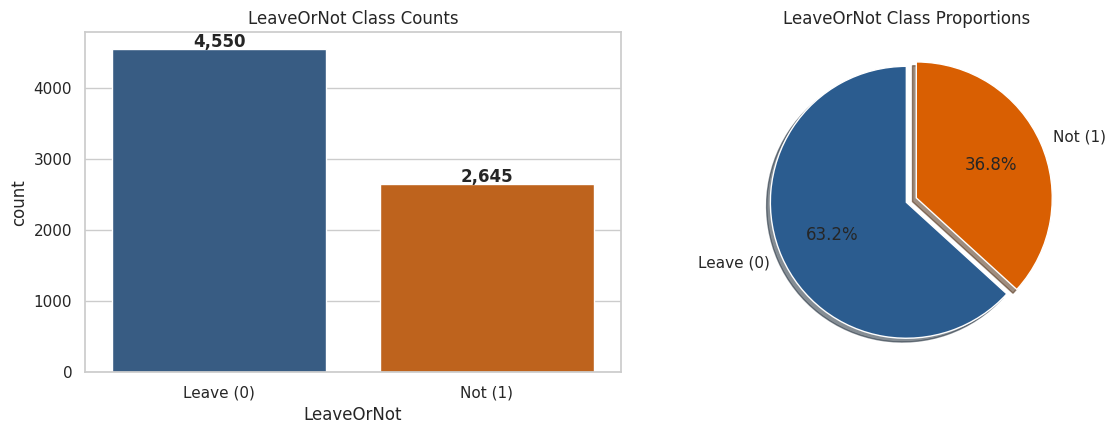

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(x="LeaveOrNot", data=df, palette=["#2b5c8f", "#d95f02"], ax=ax[0])
ax[0].set_title("LeaveOrNot Class Counts")
ax[0].set_xticklabels(["Leave (0)", "Not (1)"])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

ax[1].pie(target_2, labels=["Leave (0)", "Not (1)"], autopct="%1.1f%%",
          colors=["#2b5c8f", "#d95f02"], startangle=90, explode=(0, 0.08), shadow=True)
ax[1].set_title("LeaveOrNot Class Proportions")

plt.tight_layout()
plt.show()

### 1. Visualizing Categorical Features and their Relationship with `LeaveOrNot`

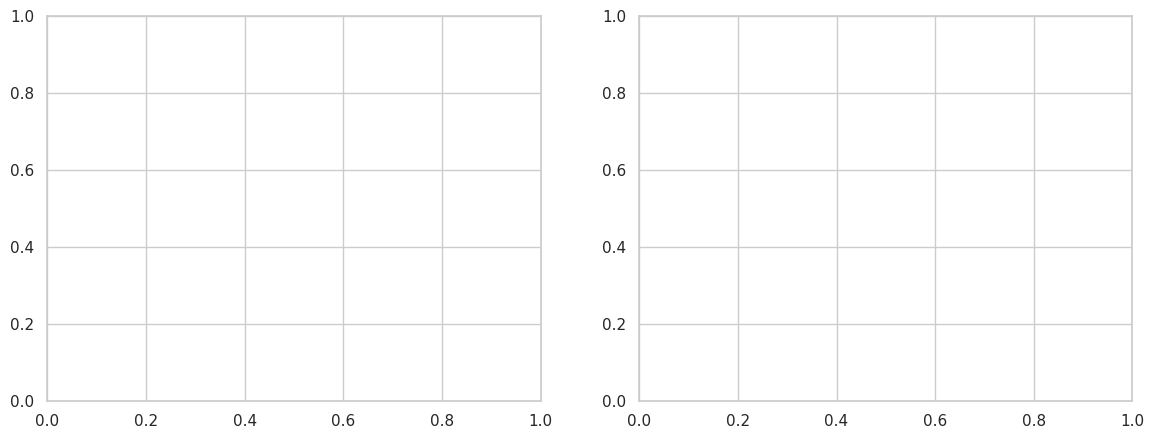

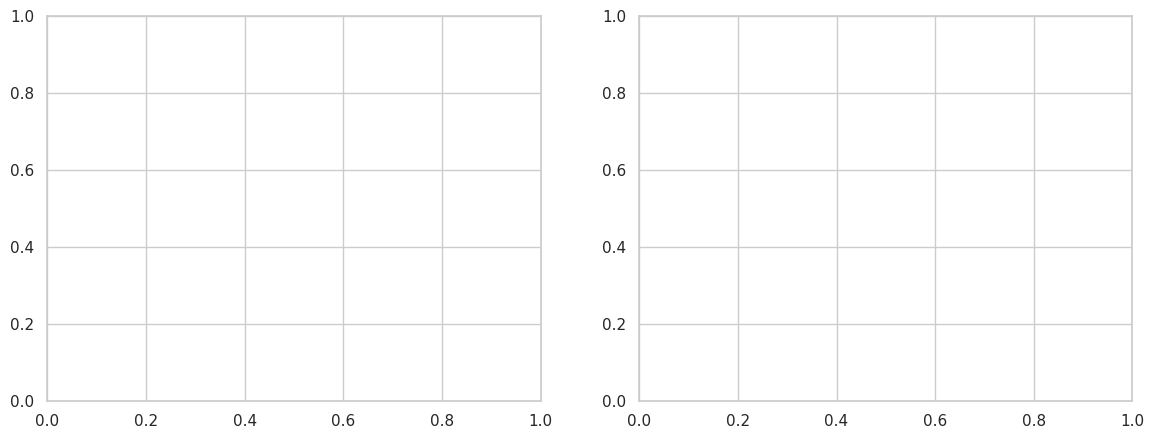

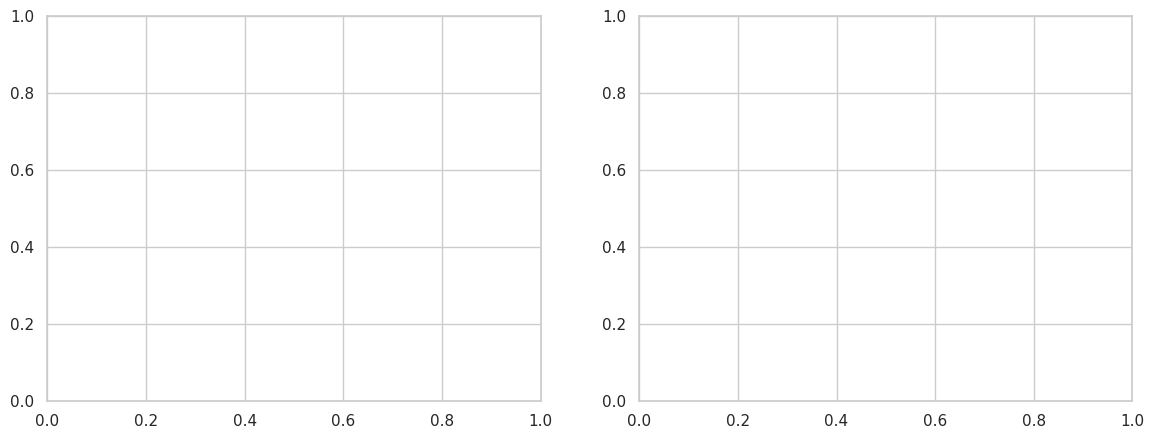

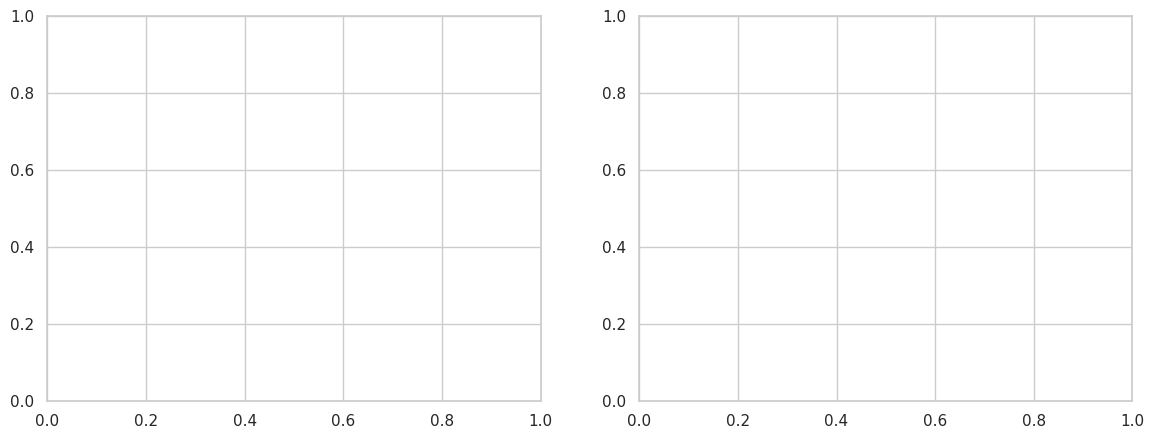

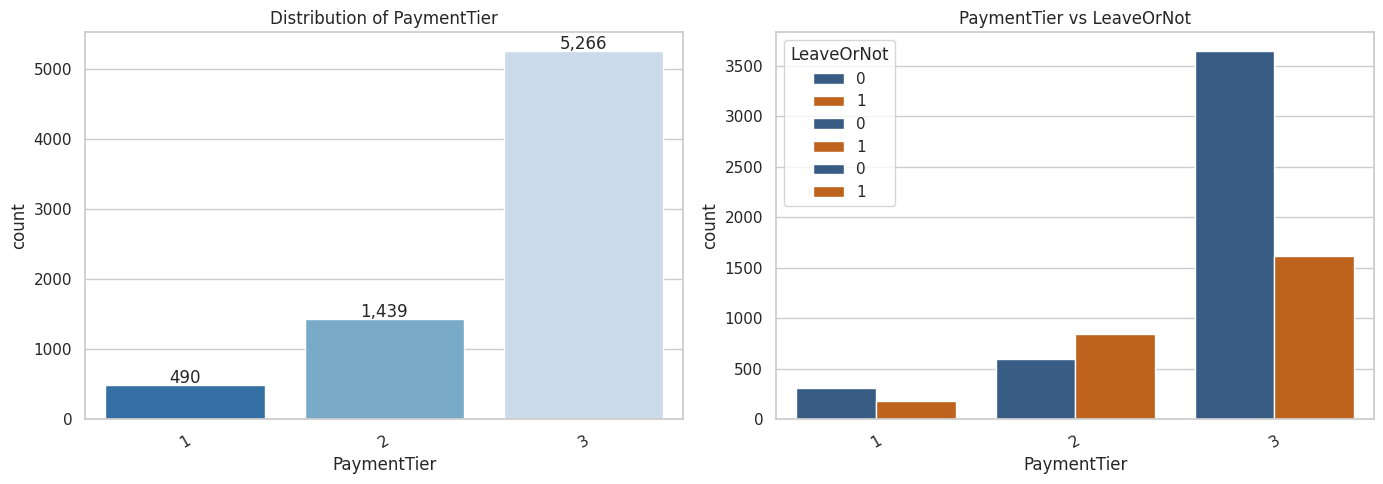

In [67]:
cat_cols = ['Education', 'City', 'Gender', 'EverBenched', 'PaymentTier']

for col in cat_cols:
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Overall count plot
sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[0])
axes[0].set_title(f'Distribution of {col}')
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
        axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 5), textcoords='offset points')

    # Relationship with target
        sns.countplot(data=df, x=col, hue='LeaveOrNot', palette=['#2b5c8f', '#d95f02'],ax=axes[1])
        axes[1].set_title(f'{col} vs LeaveOrNot')
        axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 2. Visualizing Numerical Features and their Relationship with `LeaveOrNot`

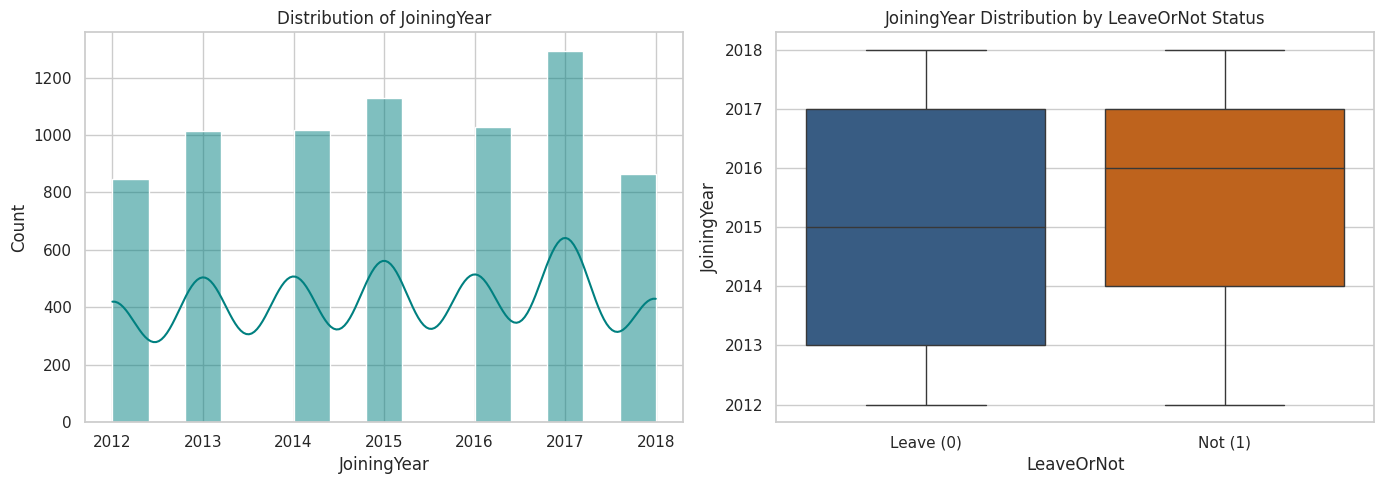

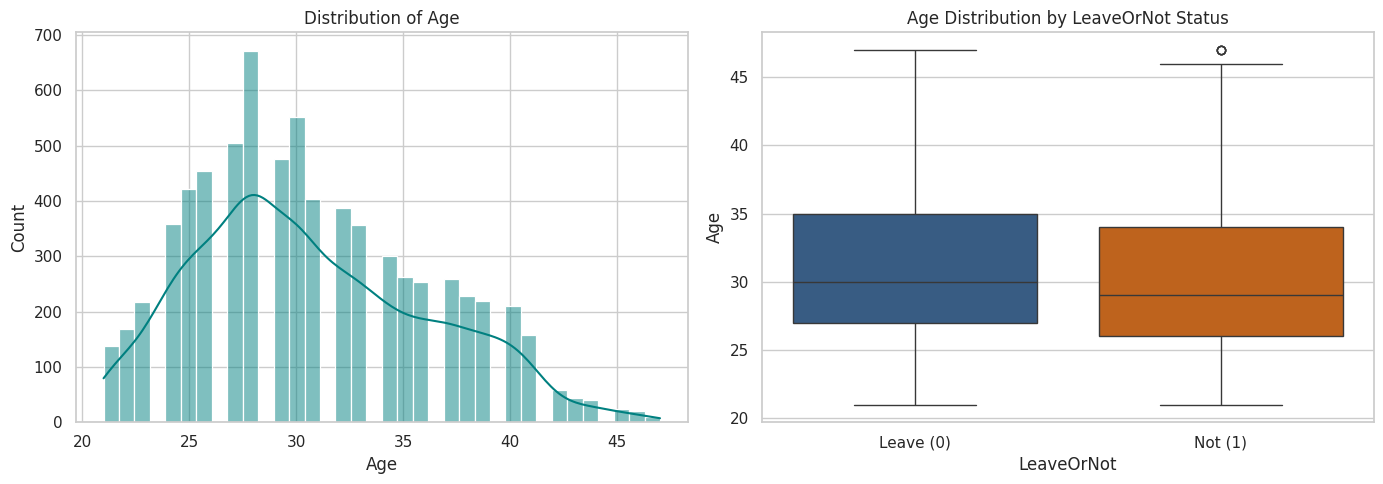

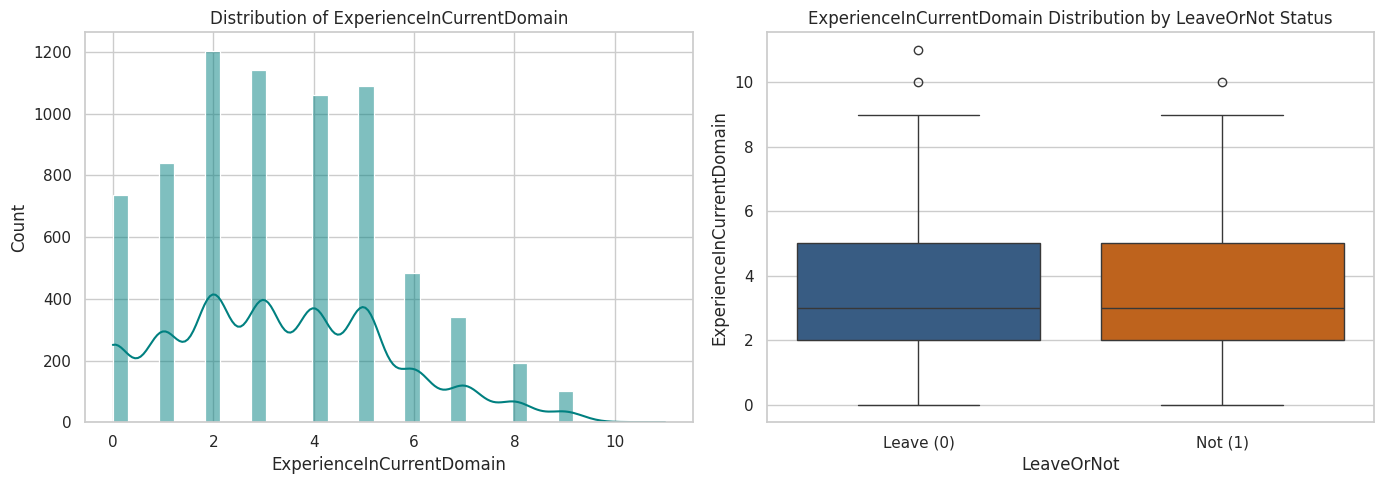

In [68]:
num_cols = ['JoiningYear', 'Age', 'ExperienceInCurrentDomain']

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Distribution histogram/kde
    sns.histplot(data=df, x=col, kde=True, color='teal', ax=axes[0])
    axes[0].set_title(f'Distribution of {col}')

    # Boxplot/Violinplot to see relationship with target
    sns.boxplot(data=df, x='LeaveOrNot', y=col, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
    axes[1].set_title(f'{col} Distribution by LeaveOrNot Status')
    axes[1].set_xticklabels(['Leave (0)', 'Not (1)'])

    plt.tight_layout()
    plt.show()

### 3. Correlation Matrix (Numerical & Encoded Variables)

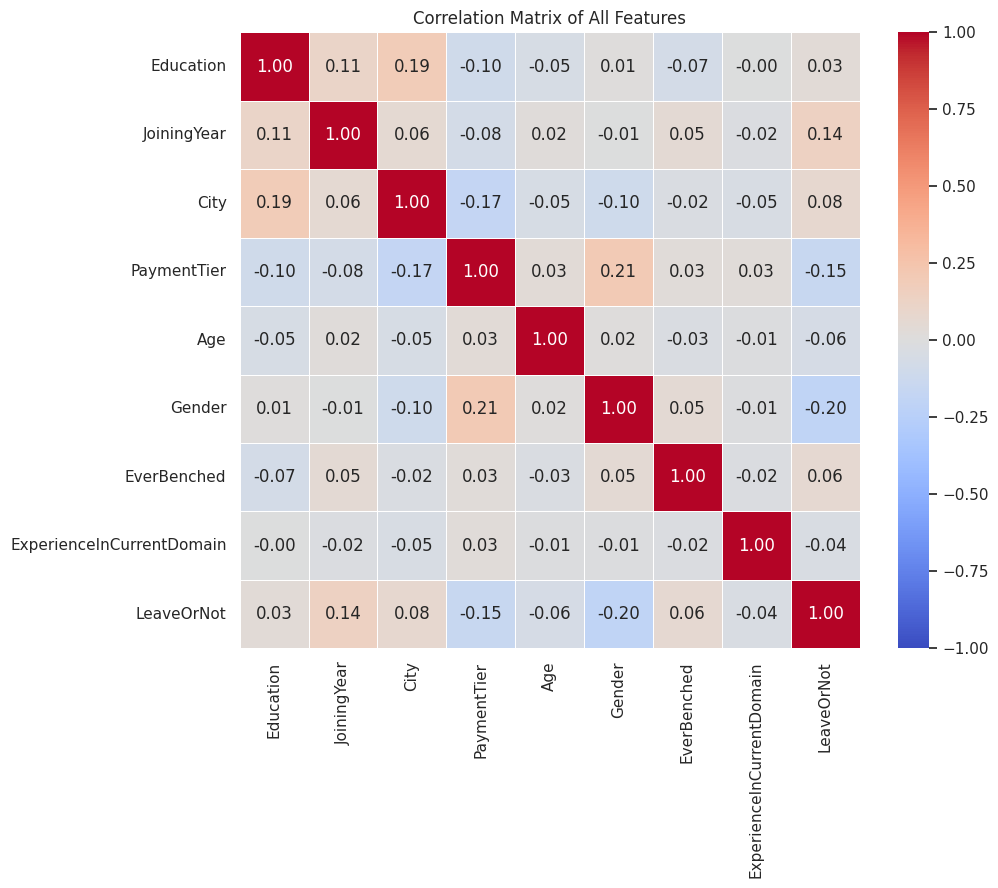

In [69]:
# Temporarily encode categorical columns to plot a correlation heatmap
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of All Features')
plt.show()

In [70]:
# Clean whitespace from categorical columns
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

# Display unique category counts per feature
print("=== UNIQUE CATEGORY COUNTS PER FEATURE ===")
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique categories")
    print(df[col].value_counts())
    print("-" * 40)

=== UNIQUE CATEGORY COUNTS PER FEATURE ===
Education: 3 unique categories
Education
Bachelors    5324
Masters      1531
PHD           340
Name: count, dtype: int64
----------------------------------------
City: 10 unique categories
City
Bangalore      1874
Pune           1220
New Delhi      1056
Hyderabad       689
Chennai         677
Ahmedabad       389
Mumbai          370
Jaipur          317
Kolkata         304
Bhubaneswar     299
Name: count, dtype: int64
----------------------------------------
Gender: 2 unique categories
Gender
Male      4133
Female    3062
Name: count, dtype: int64
----------------------------------------
EverBenched: 2 unique categories
EverBenched
No     6338
Yes     857
Name: count, dtype: int64
----------------------------------------


In [71]:
# Calculate outlier percentages using the IQR method
num_cols = ['JoiningYear', 'Age', 'ExperienceInCurrentDomain']

print("=== OUTLIER PERCENTAGES (IQR METHOD) ===")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_percentage = (len(outliers) / len(df)) * 100

    print(f"{col}: {len(outliers)} outliers found ({outlier_percentage:.2f}%)")

=== OUTLIER PERCENTAGES (IQR METHOD) ===
JoiningYear: 0 outliers found (0.00%)
Age: 54 outliers found (0.75%)
ExperienceInCurrentDomain: 3 outliers found (0.04%)


In [72]:
X = df.drop(columns=['LeaveOrNot'])
y = df['LeaveOrNot']

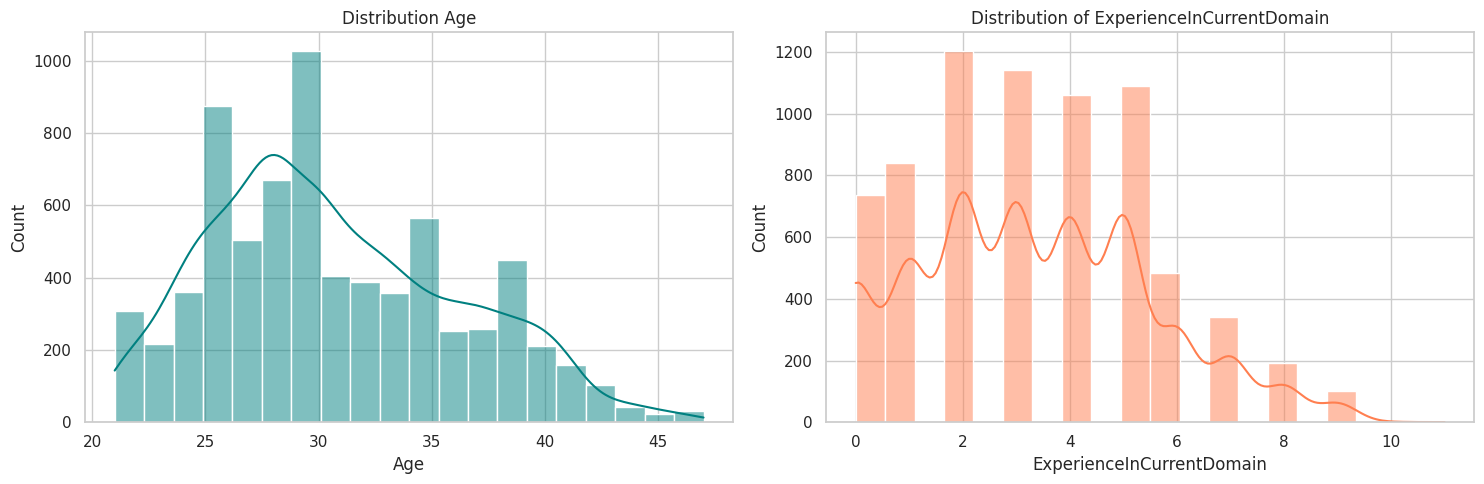

In [73]:
# Set visualization style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 5))

# Distribution of Semester 1 and 2 Attendance
plt.subplot(1, 2, 1)
sns.histplot(df['Age'], kde=True, color='teal', bins=20)
plt.title('Distribution Age')

plt.subplot(1, 2, 2)
sns.histplot(df['ExperienceInCurrentDomain'], kde=True, color='coral', bins=20)
plt.title('Distribution of ExperienceInCurrentDomain')

plt.tight_layout()
plt.show()

In [74]:
# 1. Specify input features
input_features = ["Education","JoiningYear", "City", "PaymentTier", "Gender", "Age","EverBenched", "ExperienceInCurrentDomain"]
# 2. Specify targets
targets = ["LeaveOrNot"]
X = df[input_features].copy()
Y = df[targets].copy()

print(f"Feature matrix shape: {X.shape}")
print(f"Target matrix shape: {Y.shape}")

Feature matrix shape: (7195, 8)
Target matrix shape: (7195, 1)


In [75]:
from sklearn.model_selection import train_test_split

# Split into Train and temporary test set
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.30, random_state=42)

# Split temporary set into Validation and Final Test sets
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.50,random_state=42)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")

Training set: 5036 rows
Validation set: 1079 rows
Test set: 1080 rows


In [76]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (OneHotEncoder,StandardScaler,OrdinalEncoder)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier,
    ExtraTreesClassifier)
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [86]:


# Define feature groups
numerical_cols = ['JoiningYear','Age','ExperienceInCurrentDomain']

ordinal_cols = ['Education','PaymentTier']

nominal_cols = ['City','Gender','EverBenched']


numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())])

nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numerical_cols),
        ('ordinal', ordinal_pipeline, ordinal_cols),
        ('nominal', nominal_pipeline, nominal_cols)])


In [87]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42,class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100,
    random_state=42,class_weight='balanced',n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100,random_state=42,
    class_weight='balanced',n_jobs=-1),
    'SVM': SVC(class_weight='balanced',random_state=42)}

In [88]:
results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining: {name}")
    # Create separate preprocessing pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    # Train
    pipeline.fit(X_train, np.ravel(Y_train))

    # Validation prediction
    val_preds = pipeline.predict(X_val)

    # Evaluation
    accuracy = accuracy_score(Y_val, val_preds)

    precision = precision_score(Y_val, val_preds, average='weighted',zero_division=0)

    recall = recall_score(Y_val, val_preds, average='weighted',zero_division=0)

    f1 = f1_score(Y_val, val_preds, average='weighted',zero_division=0)

    macro_f1 = f1_score(Y_val, val_preds,average='macro',zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1_Weighted': f1,
        'F1_Macro': macro_f1
    })

    trained_models[name] = pipeline


Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Training: Gradient Boosting

Training: Extra Trees

Training: SVM


In [80]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='F1_Macro',ascending=False).reset_index(drop=True)
print("\n========== MODEL COMPARISON ==========\n")
print(results_df.round(4).to_string(index=False))


========== MODEL COMPARISON ==========

              Model  Accuracy  Precision  Recall  F1_Weighted  F1_Macro
                SVM    0.7850     0.7832  0.7850       0.7827    0.7716
  Gradient Boosting    0.7896     0.8064  0.7896       0.7773    0.7605
      Random Forest    0.7303     0.7268  0.7303       0.7263    0.7114
        Extra Trees    0.7118     0.7084  0.7118       0.7092    0.6946
      Decision Tree    0.6701     0.6764  0.6701       0.6722    0.6612
Logistic Regression    0.6645     0.6741  0.6645       0.6673    0.6572


In [81]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print("\n========== BEST MODEL ==========")
print("Best Model:", best_model_name)
print("Validation Accuracy:",
    round(results_df.iloc[0]['Accuracy'], 4))
print("Validation Macro F1:",
    round(results_df.iloc[0]['F1_Macro'], 4))


========== BEST MODEL ==========
Best Model: SVM
Validation Accuracy: 0.785
Validation Macro F1: 0.7716


In [82]:
best_preds = best_model.predict(X_val)

print("\n========== CLASSIFICATION REPORT ==========\n")

print(classification_report(Y_val,best_preds,zero_division=0))


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

           0       0.80      0.85      0.83       648
           1       0.76      0.68      0.72       431

    accuracy                           0.78      1079
   macro avg       0.78      0.77      0.77      1079
weighted avg       0.78      0.78      0.78      1079



In [85]:
print(confusion_matrix(Y_val, best_preds))

[[554  94]
 [138 293]]


### 4. Hyperparameter Tuning & Cross-Validation
We will use `GridSearchCV` combined with our pipeline on the training data (`X_train`) to optimize the SVM hyperparameters (`C` and `gamma`) while maintaining zero data leakage.

In [91]:
from sklearn.model_selection import GridSearchCV

# Recreate our baseline SVM pipeline structure
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(class_weight='balanced', random_state=42))
])

# Define parameter grid (specifying the pipeline prefix 'classifier__')
param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1]
}

# Initialize GridSearchCV with 5-fold Cross-Validation
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV strictly on X_train and Y_train
grid_search.fit(X_train, Y_train.values.ravel())

# Output the best parameters
print("=== BEST HYPERPARAMETERS ===")
print(grid_search.best_params_)
print(f"Best Cross-Validation Macro F1: {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 12 candidates, totalling 60 fits
=== BEST HYPERPARAMETERS ===
{'classifier__C': 10, 'classifier__gamma': 'scale'}
Best Cross-Validation Macro F1: 0.7471


### 5. Final Evaluation on Validation & Test Sets
Now, we evaluate our optimized model on both our validation set (`X_val`) and our untouched test set (`X_test`) to verify final model generalization.

In [90]:
# Get the best estimator pipeline from our grid search
best_tuned_pipeline = grid_search.best_estimator_

# Evaluate on Validation Set
final_val_preds = best_tuned_pipeline.predict(X_val)
print("=== FINAL VALIDATION SET REPORT ===")
print(classification_report(Y_val, final_val_preds, zero_division=0))

# Evaluate on Test Set
final_test_preds = best_tuned_pipeline.predict(X_test)
print("\n=== FINAL TEST SET REPORT ===")
print(classification_report(Y_test, final_test_preds, zero_division=0))


=== FINAL VALIDATION SET REPORT ===
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       648
           1       0.78      0.67      0.72       431

    accuracy                           0.79      1079
   macro avg       0.79      0.77      0.78      1079
weighted avg       0.79      0.79      0.79      1079


=== FINAL TEST SET REPORT ===
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       697
           1       0.73      0.67      0.70       383

    accuracy                           0.80      1080
   macro avg       0.78      0.77      0.77      1080
weighted avg       0.79      0.80      0.79      1080



### 6. Model Interpretation: Permutation Feature Importance
Because SVM with non-linear kernels does not provide coefficient weights or default tree-based feature importances, we use **Permutation Feature Importance** on the test set to determine which features contribute most to our model's performance.

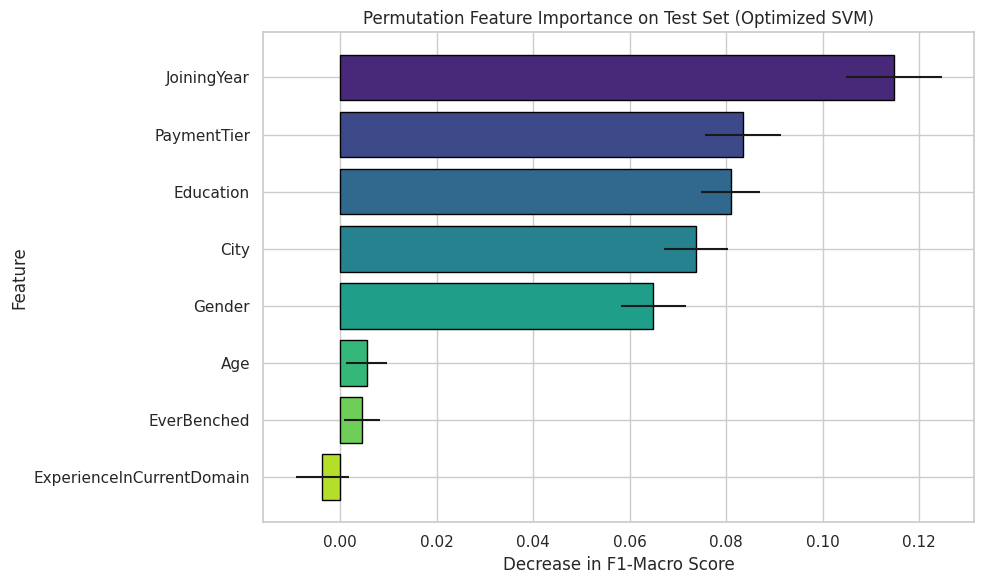

,Feature,Importance_Mean,Importance_Std
1,JoiningYear,0.114722,0.009959
3,PaymentTier,0.083519,0.007952
0,Education,0.080926,0.006103
2,City,0.073704,0.006602
4,Gender,0.064907,0.006785
5,Age,0.005556,0.004243
6,EverBenched,0.004537,0.003668
7,ExperienceInCurrentDomain,-0.003704,0.005540


In [93]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate permutation importance on the test set
result = permutation_importance(
    best_tuned_pipeline, X_test, Y_test.values.ravel(),
    n_repeats=10, random_state=42, n_jobs=-1
)

# Organize results into a DataFrame
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

# Plot the feature importances using pure matplotlib to prevent Seaborn xerr mismatch
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance_Mean'],
    xerr=importance_df['Importance_Std'],
    color=sns.color_palette('viridis', len(importance_df)),
    edgecolor='black'
)
plt.gca().invert_yaxis()  # Put most important features at the top
plt.title('Permutation Feature Importance on Test Set (Optimized SVM)')
plt.xlabel('Decrease in F1-Macro Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Display the raw values
display(importance_df)

### 7. Helper Function for Predicting Employee Churn
We'll define a robust inference function `predict_employee_churn` that takes raw input data, verifies the necessary columns, and outputs the prediction.

In [94]:
def predict_employee_churn(input_data, pipeline=best_tuned_pipeline):
    """
    Predicts whether employees will leave (1) or stay (0) given their characteristics.

    Parameters:
    -----------
    input_data : dict or pd.DataFrame
        The raw input data for one or more employees.
    pipeline : sklearn.pipeline.Pipeline
        The trained model pipeline (which includes preprocessing and the classifier).

    Returns:
    --------
    pd.DataFrame
        A dataframe containing the input features, the predicted class, and probability scores (if available).
    """
    # Ensure input is a DataFrame
    if isinstance(input_data, dict):
        df_input = pd.DataFrame([input_data])
    elif isinstance(input_data, pd.DataFrame):
        df_input = input_data.copy()
    else:
        raise ValueError("Input data must be a dictionary or a pandas DataFrame.")

    # Ensure columns are stripped of any whitespaces, matching our training preprocess
    cat_cols = df_input.select_dtypes(include=['object']).columns
    for col in cat_cols:
        df_input[col] = df_input[col].astype(str).str.strip()

    # Make predictions
    predictions = pipeline.predict(df_input)

    # Create output DataFrame
    output_df = df_input.copy()
    output_df['Predicted_Leave'] = predictions
    output_df['Predicted_Status'] = output_df['Predicted_Leave'].map({0: "Will Stay", 1: "Will Leave"})

    # SVM with RBF/GridSearch doesn't always have probability enabled unless probability=True is specified in SVC
    # If the classifier has predict_proba, we include confidence
    if hasattr(pipeline.named_steps['classifier'], 'predict_proba'):
        probabilities = pipeline.predict_proba(df_input)[:, 1]
        output_df['Churn_Probability'] = probabilities

    return output_df

Let's demonstrate using our new function with a couple of mock employee profiles.

In [101]:
# Example 1: Single employee profile as a dictionary
new_employee_1 = {
    'Education': 'Bachelors',
    'JoiningYear': 2018,
    'City': 'Bangalore',
    'PaymentTier': 3,
    'Gender': 'Male',
    'Age': 26,
    'EverBenched': 'No',
    'ExperienceInCurrentDomain': 4
}

# Example 2: Multiple employee profiles in a DataFrame
new_employees_df = pd.DataFrame([
    {
        'Education': 'Bachelors',
        'JoiningYear': 2016,
        'City': 'Pune',
        'PaymentTier': 1,
        'Gender': 'Male',
        'Age': 28,
        'EverBenched': 'No',
        'ExperienceInCurrentDomain': 7
    },
    {
        'Education': 'PHD',
        'JoiningYear': 2013,
        'City': 'New Delhi',
        'PaymentTier': 3,
        'Age': 40,
        'Gender': 'Female',
        'EverBenched': 'Yes',
        'ExperienceInCurrentDomain': 1
    }
])

print("=== PREDICTION FOR EMPLOYEE 1 ===")
res_1 = predict_employee_churn(new_employee_1)
display(res_1[['Education', 'City', 'JoiningYear', 'Predicted_Status']])

print("\n=== PREDICTIONS FOR BATCH ===")
res_batch = predict_employee_churn(new_employees_df)
display(res_batch[['Education', 'City', 'JoiningYear', 'Predicted_Status']])

=== PREDICTION FOR EMPLOYEE 1 ===


,Education,City,JoiningYear,Predicted_Status
0,Bachelors,Bangalore,2018,Will Leave



=== PREDICTIONS FOR BATCH ===


,Education,City,JoiningYear,Predicted_Status
0,Bachelors,Pune,2016,Will Stay
1,PHD,New Delhi,2013,Will Leave


### 8. Save the Optimized Model Pipeline
We use the `joblib` library to serialize the trained `best_tuned_pipeline` and save it as a `.joblib` file.

In [107]:
import joblib

# Define model path
model_filename = 'optimized_svm_churn_pipeline.pkl'

# Save pipeline
joblib.dump(best_tuned_pipeline, model_filename)
print(f"Successfully saved the trained pipeline to: {model_filename}")

Successfully saved the trained pipeline to: optimized_svm_churn_pipeline.pkl


Let's verify that the saved model can be loaded correctly and produces predictions consistent with our earlier implementation.

In [104]:
# Load the saved pipeline
loaded_pipeline = joblib.load(model_filename)

# Test the loaded pipeline on the first mock employee
verification_pred = predict_employee_churn(new_employee_1, pipeline=loaded_pipeline)
print("=== LOADED MODEL PREDICTION VERIFICATION ===")
display(verification_pred[['Education', 'City', 'JoiningYear', 'Predicted_Status']])

=== LOADED MODEL PREDICTION VERIFICATION ===


,Education,City,JoiningYear,Predicted_Status
0,Bachelors,Bangalore,2018,Will Leave


### 9. Deploying as a FastAPI Backend Service

To serve our saved `optimized_svm_churn_pipeline.joblib` model systematically, we can construct a **FastAPI** application. We will use **Pydantic** to declare structured request schemas for validation and type-safety.

Below is the complete, self-contained Python code for the backend service.

In [106]:
# To run this locally, you can install the dependencies:
# !pip install fastapi uvicorn pydantic joblib pandas

import os
import joblib
import pandas as pd
from typing import List, Optional
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

# 1. Define the Pydantic schemas for request validation
class EmployeeRecord(BaseModel):
    Education: str = Field(..., description="Education level (e.g., Bachelors, Masters, PHD)")
    JoiningYear: int = Field(..., ge=2000, le=2030, description="The year the employee joined")
    City: str = Field(..., description="City of employment")
    PaymentTier: int = Field(..., ge=1, le=3, description="Payment Tier (1, 2, or 3)")
    Gender: str = Field(..., description="Gender of the employee (Male or Female)")
    Age: int = Field(..., ge=18, le=100, description="Age of the employee")
    EverBenched: str = Field(..., description="Whether the employee was ever benched (Yes or No)")
    ExperienceInCurrentDomain: int = Field(..., ge=0, description="Experience in current domain in years")

    class Config:
        json_schema_extra = {
            "example": {
                "Education": "Bachelors",
                "JoiningYear": 2018,
                "City": "Bangalore",
                "PaymentTier": 3,
                "Gender": "Male",
                "Age": 26,
                "EverBenched": "No",
                "ExperienceInCurrentDomain": 4
            }
        }

# Schema that keeps ALL original input fields and appends prediction outputs
class PredictionResponse(EmployeeRecord):
    Predicted_Leave: int
    Predicted_Status: str
    Churn_Probability: Optional[float] = None

# 2. Initialize the FastAPI App
app = FastAPI(
    title="Employee Churn Prediction API",
    description="FastAPI backend service serving an optimized SVM pipeline to predict employee churn.",
    version="1.0.0"
)

# 3. Load the pre-trained model on startup
MODEL_PATH = "optimized_svm_churn_pipeline.joblib"
if os.path.exists(MODEL_PATH):
    pipeline = joblib.load(MODEL_PATH)
else:
    # Fallback to in-memory variable if running in this Colab session
    try:
        pipeline = best_tuned_pipeline
    except NameError:
        pipeline = None

@app.get("/")
def read_root():
    return {
        "message": "Welcome to the Employee Churn Prediction API!",
        "status": "Model Loaded successfully" if pipeline is not None else "Model missing"
    }

# 4. Define the prediction endpoint
@app.post("/predict", response_model=List[PredictionResponse])
def predict_churn(records: List[EmployeeRecord]):
    if pipeline is None:
        raise HTTPException(status_code=500, detail="Model pipeline is not loaded on the server.")

    try:
        # Convert list of Pydantic models to pandas DataFrame
        input_data = [rec.model_dump() for rec in records]
        df_input = pd.DataFrame(input_data)

        # Clean whitespaces as expected by preprocessing
        cat_cols = df_input.select_dtypes(include=['object']).columns
        for col in cat_cols:
            df_input[col] = df_input[col].astype(str).str.strip()

        # Get model predictions
        predictions = pipeline.predict(df_input)

        # Check if probability output is supported by model
        has_proba = hasattr(pipeline.named_steps['classifier'], 'predict_proba')
        probabilities = pipeline.predict_proba(df_input)[:, 1] if has_proba else None

        # Build responses combining original inputs and prediction details
        results = []
        for i, pred in enumerate(predictions):
            prob_val = float(probabilities[i]) if probabilities is not None else None
            results.append(PredictionResponse(
                Education=df_input.iloc[i]['Education'],
                JoiningYear=int(df_input.iloc[i]['JoiningYear']),
                City=df_input.iloc[i]['City'],
                PaymentTier=int(df_input.iloc[i]['PaymentTier']),
                Gender=df_input.iloc[i]['Gender'],
                Age=int(df_input.iloc[i]['Age']),
                EverBenched=df_input.iloc[i]['EverBenched'],
                ExperienceInCurrentDomain=int(df_input.iloc[i]['ExperienceInCurrentDomain']),
                Predicted_Leave=int(pred),
                Predicted_Status="Will Leave" if pred == 1 else "Will Stay",
                Churn_Probability=prob_val
            ))

        return results

    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))

# To run this FastAPI app, save this script as `main.py` and run:
# uvicorn main:app --host 0.0.0.0 --port 8000